# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** __________________________________  
**Grupo:** __________________  **Fecha:** __________________

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})

ruta = Path('../data/raw/nyc_taxi_examen.csv')
if not ruta.is_file():
    ruta = Path('data/raw/nyc_taxi_examen.csv')
df = pd.read_csv(ruta, index_col=0)

print('Primeras 5 filas:')
display(df.head(5))
print('Dimensiones:', df.shape)
print('Columnas:', df.columns.tolist())
print('Tipos:')
display(df.dtypes.rename('tipo').to_frame())
print('Resumen:')
display(df.describe().round(2))
print('Pagos:')
display(df['payment_type'].value_counts(dropna=False).rename('viajes').to_frame())


Primeras 5 filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones: (2427612, 20)
Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']
Tipos:


,tipo
VendorID,int64
tpep_pickup_datetime,str
tpep_dropoff_datetime,str
passenger_count,float64
trip_distance,float64
RatecodeID,float64
PULocationID,float64
DOLocationID,float64
payment_type,str
fare_amount,float64


Resumen:


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2427612.00,2415489.00,2415470.00,2415474.00,2415487.00,2415475.00,2415488.00,2415487.00,2415462.00,2415459.00,2415465.00,2415481.00,2415484.00,2415457.00,2415481.00,2415462.00,2415475.00
mean,1.89,1.30,3.30,4.23,164.14,163.22,38.53,1.57,0.48,3.67,0.59,0.99,29.38,2.25,0.20,0.56,15.61
std,0.81,1.88,5.17,17.20,62.85,69.26,542.38,1.91,0.10,4.23,2.39,0.16,25.93,0.78,0.63,0.33,260.58
min,1.00,-5.00,-99.99,1.00,1.00,1.00,-1849.60,-7.50,-0.50,-90.00,-106.46,-1.00,-1866.89,-2.50,-2.00,-0.75,-300517.52
25%,2.00,1.00,0.99,1.00,132.00,113.00,9.30,0.00,0.50,1.00,0.00,1.00,16.38,2.50,0.00,0.75,7.28
50%,2.00,1.00,1.70,1.00,161.00,162.00,13.50,1.00,0.50,2.95,0.00,1.00,21.54,2.50,0.00,0.75,12.32
75%,2.00,1.00,3.36,1.00,232.00,234.00,21.90,2.50,0.50,4.56,0.00,1.00,31.45,2.50,0.00,0.75,20.12
max,7.00,100.00,1686.49,99.00,265.00,265.00,19995.59,23.25,11.50,444.44,616.79,1.00,5530.74,2.75,27.00,0.75,8373.67


Pagos:


,viajes
payment_type,
Credit card,2051983
Cash,329533
Dispute,23558
NaN,12125
No charge,10413


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
df_limpio = df.copy()
print('Antes:', df_limpio.shape)
print('Nulos:')
display(df_limpio.isna().sum().rename('nulos').to_frame())
print('Duplicados:', df_limpio.duplicated().sum())

df_limpio = df_limpio.drop_duplicates().dropna()
condiciones_validas = (
    (df_limpio['trip_distance'] > 0)
    & (df_limpio['passenger_count'] > 0)
    & (df_limpio['passenger_count'] < 100)
    & (df_limpio['fare_amount'] > 0)
    & (df_limpio['fare_amount'] < 10000)
    & (df_limpio['trip_duration'] > 0)
)
df_limpio = df_limpio.loc[condiciones_validas].copy()

print('Después:', df_limpio.shape)
print(f'Filas: {len(df_limpio):,}')


Antes: (2427612, 20)
Nulos:


,nulos
VendorID,0
tpep_pickup_datetime,12126
tpep_dropoff_datetime,12127
passenger_count,12123
trip_distance,12142
RatecodeID,12138
PULocationID,12125
DOLocationID,12137
payment_type,12125
fare_amount,12124


Duplicados: 11961


Después: (2096600, 20)
Filas: 2,096,600


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [ ]:
df_cash = df_limpio.loc[df_limpio['payment_type'].eq('Cash')].copy()
variables = ['trip_distance', 'trip_duration']
X = df_cash[variables].copy()

print(f'Viajes Cash: {len(df_cash):,}')
display(X.describe().round(2))


Viajes Cash: 282,085


,trip_distance,trip_duration
count,282085.00,282085.00
mean,3.84,17.51
std,6.21,40.68
min,0.01,0.03
25%,0.92,7.40
50%,1.70,12.42
75%,4.37,20.88
max,1686.49,8373.67


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [4]:
X_log = np.log1p(X)
scaler = StandardScaler()
X_escalado = pd.DataFrame(
    scaler.fit_transform(X_log), columns=X.columns, index=X.index
)

print('Log1p:')
display(X_log.describe().round(4))
print('Estandarizado:')
display(X_escalado.describe().round(4))


Log1p:


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,1.2255,2.6076
std,0.7633,0.7445
min,0.0100,0.0328
25%,0.6523,2.1282
50%,0.9933,2.5965
75%,1.6808,3.0857
max,7.4310,9.0330


Estandarizado:


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,0.0000,-0.0000
std,1.0000,1.0000
min,-1.5924,-3.4587
25%,-0.7509,-0.6439
50%,-0.3042,-0.0149
75%,0.5966,0.6422
max,8.1299,8.6310


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,227681.23,0.531989
1,3,137511.96,0.447811
2,4,100620.19,0.419141
3,5,79205.37,0.389450
4,6,66980.31,0.373718


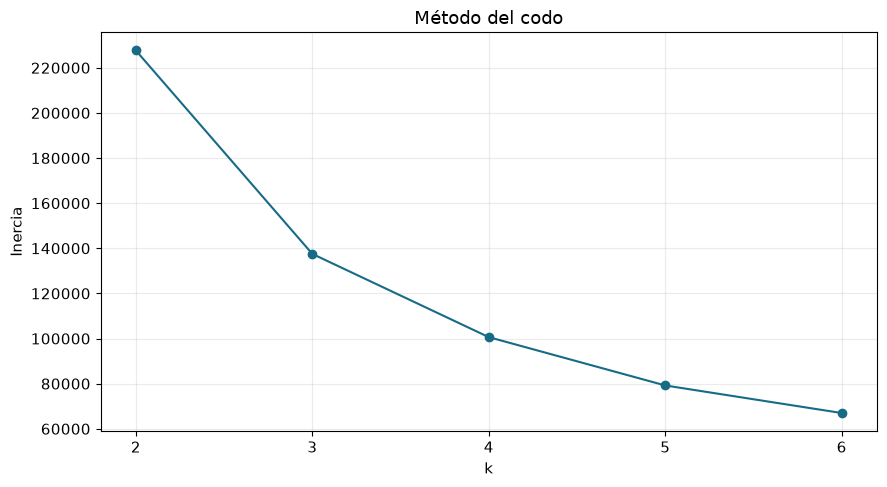

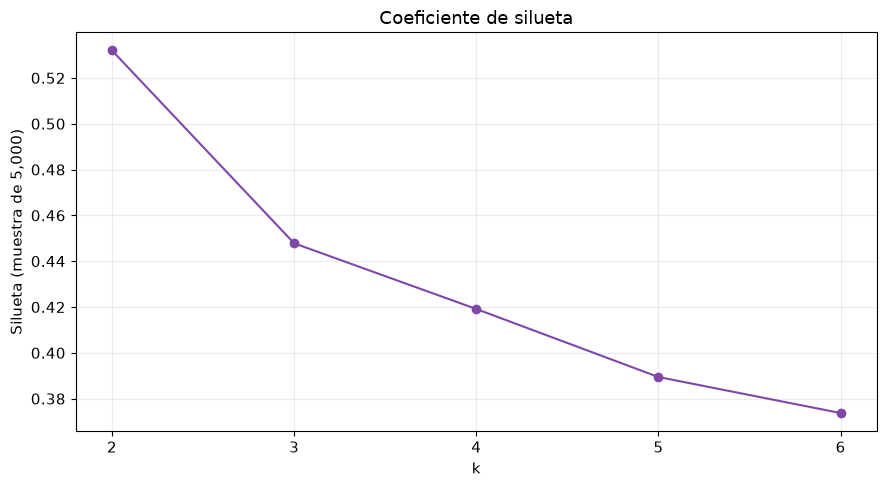

In [5]:
resultados_k = []
for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo_k.fit_predict(X_escalado)
    silueta = silhouette_score(
        X_escalado, etiquetas_k, sample_size=5000, random_state=42
    )
    resultados_k.append({
        'k': k, 'Inercia': modelo_k.inertia_, 'Silueta': silueta
    })

tabla_k = pd.DataFrame(resultados_k)
display(tabla_k.round({'Inercia': 2, 'Silueta': 6}))

fig, ax = plt.subplots()
ax.plot(tabla_k['k'], tabla_k['Inercia'], marker='o', color='#176B87')
ax.set(title='Método del codo', xlabel='k', ylabel='Inercia')
ax.set_xticks(tabla_k['k'])
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(tabla_k['k'], tabla_k['Silueta'], marker='o', color='#8046A8')
ax.set(title='Coeficiente de silueta', xlabel='k',
       ylabel='Silueta (muestra de 5,000)')
ax.set_xticks(tabla_k['k'])
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

k: 2


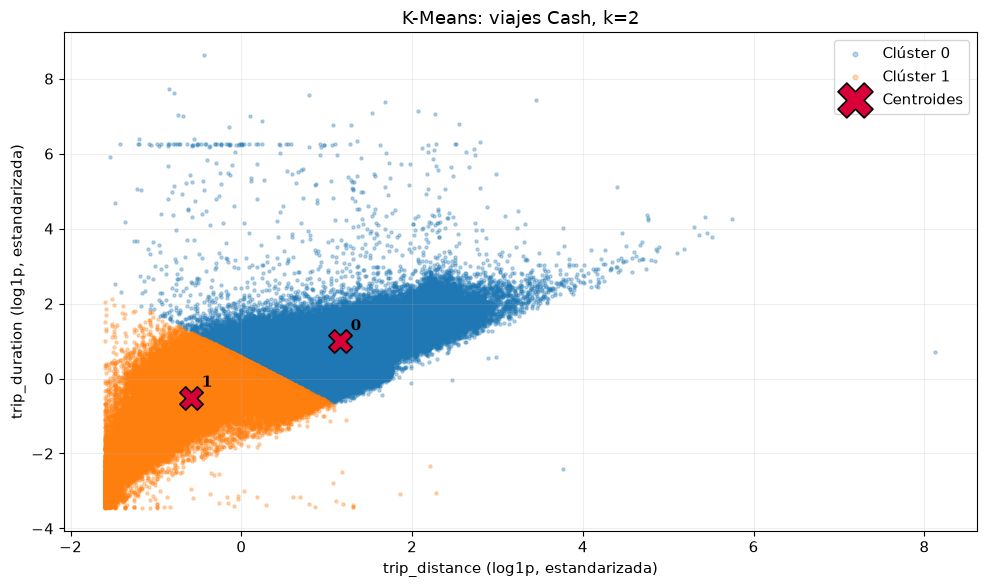

In [6]:
k_elegido = int(tabla_k.loc[tabla_k['Silueta'].idxmax(), 'k'])
print('k:', k_elegido)

modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
etiquetas = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_

fig, ax = plt.subplots(figsize=(10, 6))
colores = plt.get_cmap('tab10')
for cluster in range(k_elegido):
    puntos = X_escalado.loc[etiquetas == cluster]
    ax.scatter(puntos['trip_distance'], puntos['trip_duration'],
               s=5, alpha=0.30, color=colores(cluster),
               label=f'Clúster {cluster}', rasterized=True)
ax.scatter(centroides[:, 0], centroides[:, 1], marker='X',
           s=280, c='#D90039', edgecolors='black', linewidths=1.2,
           label='Centroides', zorder=5)
for cluster, (cx, cy) in enumerate(centroides):
    ax.annotate(str(cluster), (cx, cy), xytext=(8, 8),
                textcoords='offset points', fontweight='bold')
ax.set(title=f'K-Means: viajes Cash, k={k_elegido}',
       xlabel='trip_distance (log1p, estandarizada)',
       ylabel='trip_duration (log1p, estandarizada)')
ax.legend(markerscale=1.5)
ax.grid(alpha=0.20)
fig.tight_layout()
plt.show()


## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
df_resultado = df_cash.copy()
df_resultado['cluster'] = etiquetas

estadisticos_cluster = df_resultado.groupby('cluster').agg(
    cantidad_viajes=('trip_distance', 'size'),
    distancia_media_millas=('trip_distance', 'mean'),
    distancia_mediana_millas=('trip_distance', 'median'),
    duracion_media_minutos=('trip_duration', 'mean'),
    duracion_mediana_minutos=('trip_duration', 'median'),
)
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(estadisticos_cluster.round(2))


,cantidad_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_minutos,duracion_mediana_minutos
cluster,,,,,
0,95794,8.82,7.06,33.04,25.85
1,186291,1.28,1.13,9.52,8.95


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

Respuesta: Elegí 2 grupos porque tuvieron la silueta más alta, 0.532. Con 3 grupos la inercia bajó de 227,681.23 a 137,511.96, pero la silueta también bajó a 0.448. Por eso me quedé con 2, que permiten distinguir entre viajes cortos y largos.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

Respuesta: Al grupo 0 le pondría "viajes largos". Tiene 95,794 viajes. Su distancia promedio es de 8.82 millas y su mediana de 7.06. Duran en promedio 33.04 minutos y su mediana es de 25.85.

Al grupo 1 le pondría "viajes cortos". Tiene 186,291 viajes. Su distancia promedio es de 1.28 millas y su mediana de 1.13. Duran en promedio 9.52 minutos y su mediana es de 8.95. En general, estos viajes recorren menos distancia y tardan menos.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

Respuesta: El grupo 0 tiene la mayor duración promedio, con 33.04 minutos. También tiene la mayor distancia promedio, con 8.82 millas. El grupo 1 tiene valores menores: 9.52 minutos y 1.28 millas.

**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

Respuesta: El grupo 1 es el más grande, con 186,291 viajes, que son el 66.04% del total. Son viajes cortos, con un promedio de 1.28 millas y 9.52 minutos.


---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**